## Global sensitivity analysis of the spinning dust SED features to the grain and environmental parameters.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings('ignore')

# Add the root directory of the package to sys.path
sys.path.append('/Users/zzhang/Workspace/SpyDust/')
sys.path.append('../')

In [2]:
# Configure matplotlib for publication quality
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'Bitstream Vera Serif', 'serif'],
    'text.usetex': False,  # Set to True if LaTeX is available
    'figure.figsize': [10, 8],
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'axes.linewidth': 1.2,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'lines.linewidth': 2,
    'lines.markersize': 6
})

In [3]:
# Check which font is actually being used
import matplotlib.font_manager as fm
font_prop = fm.FontProperties(family='serif')
print(f"Active serif font: {font_prop.get_name()}")
print(f"Available serif fonts: {[f.name for f in fm.fontManager.ttflist if 'serif' in f.name.lower()][:5]}")  # Show first 5

Active serif font: Times New Roman
Available serif fonts: ['DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif Display', 'DejaVu Serif']


In [4]:
# Import SpyDust modules
import functools
import SpyDust.Grain as Grain
from SpyDust.SpyDust import SpyDust_given_grain_size_shape
from SpyDust.util import makelogtab, cgsconst
from SpyDust.SPDUST_as_is import emissivity
import matplotlib.cm as cm


l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
Gaunt factor stored
l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Maximum energy in the Qabs_hnu_tab is 1239.84 eV.
FIR_integral_charged shape: (30, 30)
Na: 30, Nchi: 30
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
Gaunt factor stored


In [5]:
freqs = np.loadtxt('data_revision/freq.txt')
DC_params = np.loadtxt('data_revision/DC_params.txt')
DC_sed_tumbling = np.loadtxt('data_revision/DC_SED_tumbling.txt')
# DC_sed_no_tumbling = np.loadtxt('data/DC_SED_no_tumbling.txt')

# Remove unphysical SEDs (nan or negative values)
valid_indices_tumbling = ~np.isnan(DC_sed_tumbling).any(axis=1) & (DC_sed_tumbling > 0).all(axis=1)
DC_sed_tumbling = DC_sed_tumbling[valid_indices_tumbling]
DC_params_tumbling = DC_params[valid_indices_tumbling]

# valid_indices_no_tumbling = ~np.isnan(DC_sed_no_tumbling).any(axis=1) & (DC_sed_no_tumbling > 0).all(axis=1)
# DC_sed_no_tumbling = DC_sed_no_tumbling[valid_indices_no_tumbling]
# DC_params_no_tumbling = DC_params[valid_indices_no_tumbling]

from SpyDust.SED_fit import fit_sed_ensemble

DC_features_tumbling = fit_sed_ensemble(
    freqs,
    DC_sed_tumbling,
    thres=1e-3, 
)
DC_features_tumbling[:,0] = np.exp(DC_features_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

# DC_features_no_tumbling = fit_sed_ensemble(
#     freqs,
#     DC_sed_no_tumbling,
#     thres=1e-3, 
#     v2=False
# )
# DC_features_no_tumbling[:,0] = np.exp(DC_features_no_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

100%|██████████| 100000/100000 [00:15<00:00, 6368.67it/s]


In [6]:
DC_catalogue = [[25.7, 0.59], 
                [18.3, 0.58],
                [16.5, 0.70],
                [21.8, 0.57],
                [18.2, 0.64],
                [18.7, 0.66],
                [21.7, 0.68],
                [22.7, 0.66],
                [23.3, 0.54],
                [21.7, 0.57],
                [26.2, 0.54],
                [20.2, 0.59],
                [14.7, 0.52],
                [16.4, 0.68],
                [24.4, 0.49],
                [26.7, 0.64],
                [16.3, 0.52],
                [18.4, 0.64],
                [20.8, 0.64],
                [23.4, 0.41],
                [19.6, 0.89],
                [18.3, 0.43],
                [19.1, 0.53],
                [20.1, 0.59],
                [19.8, 0.64],
                [22.4, 0.47],
                [20.9, 0.57],
                [26.6, 0.59],
                [19.1, 0.51],
                [18.1, 0.54],
                [27.1, 0.96],
                [25.2, 0.58],
                [23.5, 0.49],
                [23.7, 0.45],
                [25.1, 0.65],
                [19.4, 0.52],
                [20.7, 0.69],
                [17.8, 0.47],
                [20.3, 0.68],
                [24.2, 0.49]
                ]

DC_catalogue = np.array(DC_catalogue)

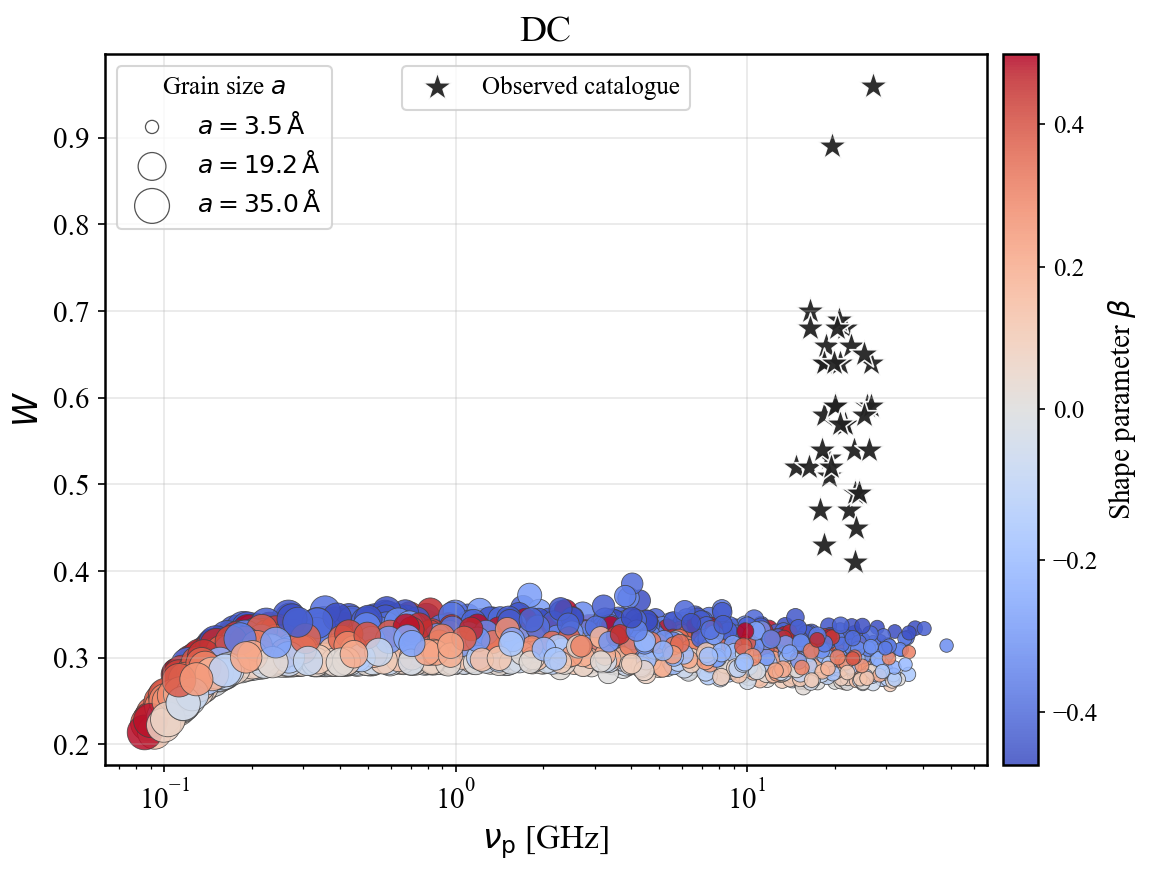

In [29]:
import matplotlib.colors as mcolors

Num=2000

grain_sizes = DC_params_tumbling[:Num, -2]  # typically the sampled grain size a
beta_values = DC_params_tumbling[:Num, -1]   # typically the shape parameter beta

size_min = grain_sizes.min()
size_max = grain_sizes.max()

size_span = size_max - size_min if size_max > size_min else 1.0

size_min_area = 40.0
size_max_area = 280.0

def _marker_area(values):
    values = np.asarray(values)
    fraction = (values - size_min) / size_span
    scaled = np.clip(fraction, 0.0, 1.0) ** 0.8  # soften the dynamic range
    return size_min_area + (size_max_area - size_min_area) * scaled

marker_sizes = _marker_area(grain_sizes)

if np.any(beta_values < 0) and np.any(beta_values > 0):
    norm = mcolors.TwoSlopeNorm(vmin=beta_values.min(), vcenter=0.0, vmax=beta_values.max())
else:
    norm = mcolors.Normalize(vmin=beta_values.min(), vmax=beta_values.max())

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    DC_features_tumbling[:Num, 0],
    DC_features_tumbling[:Num, 1],
    c=beta_values,
    cmap="coolwarm",
    norm=norm,
    s=marker_sizes,
    alpha=0.85,
    edgecolors="0.25",
    linewidth=0.4
)

# scatter_no_tumbling = ax.scatter(
#     DC_features_no_tumbling[:Num, 0],
#     DC_features_no_tumbling[:Num, 1],
#     c="lightgray",
#     norm=norm,
#     s=marker_sizes,
#     alpha=0.85,
#     edgecolors="0.25",
#     linewidth=0.4
# )

obs_handle = ax.scatter(
    DC_catalogue[:, 0],
    DC_catalogue[:, 1],
    marker="*",
    s=220,
    c="#222222",
    edgecolors="white",
    linewidth=0.8,
    alpha=0.95,
    label="Observed catalogue"
)

ax.set_xlabel(r"$\nu_{\rm p}$ [GHz]", fontsize=16)
ax.set_ylabel(r"$W$", fontsize=16)
ax.set_xscale("log")
ax.grid(True, alpha=0.3)
ax.tick_params(axis="both", which="both", labelsize=14)

cbar = plt.colorbar(scatter, ax=ax, pad=0.015)
cbar.set_label(r"Shape parameter $\beta$", fontsize=14)
cbar.ax.tick_params(labelsize=12)

size_labels = np.linspace(size_min, size_max, 3)
size_handles = [
    ax.scatter([], [], s=_marker_area(val), facecolors="none", edgecolors="0.25", linewidth=0.6, alpha=0.9,
               label=fr"$a = {val*1e8:.1f}\,\mathrm{{\AA}}$")
    for val in size_labels
]

legend1 = ax.legend(
    handles=size_handles,
    title=r"Grain size $a$",
    loc="upper left",
    frameon=True,
    fontsize=12,
    title_fontsize=12
)
ax.add_artist(legend1)

legend2 = ax.legend([obs_handle], ["Observed catalogue"], loc="upper center", frameon=True, fontsize=12)

ax.set_title("DC", fontsize=18)

plt.savefig("DC_catalogue_single.pdf")

plt.tight_layout()
plt.show()

In [24]:
# X=DC_params_no_tumbling
import copy

# Get indices where peak frequencies are larger than 5GHz.
X = copy.deepcopy(DC_params_tumbling)
Y= copy.deepcopy(DC_features_tumbling)

mask = (Y[:, 0] > 10) & (Y[:, 0] < 100)
idx = np.where(mask)[0]
print(f"Selected {len(idx)} samples out of {X.shape[0]} based on peak frequency criteria.")

X=X[idx, :]
Y=Y[idx, :]

Num=5000
X=X[:Num, :]
Y=Y[:Num, :]

X[:,-2] = np.log(X[:,-2] )


from mcpost import gsa_pipeline
# Reload the module to get latest changes
# import importlib
# importlib.reload(sys.modules['gsa_pipeline'])
# from gsa_pipeline import gsa_pipeline


# Your arrays
# X: (N_samples, N_params)
# Y: (N_samples, 2)  # columns: [peak_frequency, width]
param_names = ["nh","T","Chi","xh","xC","y", "dipole", "a","beta"]  # adjust to your order

out = gsa_pipeline(
    X, Y,
    feature_names=["nu_peak", "width"],
    param_names=param_names,
    scaler="standard",            # try "minmax" or None as well
    kernel_kind="rbf",             # try "rbf", "matern32", "matern52", "rq"
    ard=True,
    length_scale_init=1.0,        # or np.ones(d_kept) after dropping consts (handled internally)
    enable_perm=True,
    enable_gp=True,
    enable_sobol=True,
    make_pdp=True,
    N_sobol=1024,                 # increase for tighter Sobol CIs
    drop_const_atol=0.0,
    topk_pdp=3,
    pdp_prefix="pdp_demo",
    gp_random_state=0,
)

table_peak  = out["results"]["nu_peak"]["table"]
table_width = out["results"]["width"]["table"]

Selected 22205 samples out of 100000 based on peak frequency criteria.


In [26]:
# from gsa_pipeline import gsa_pipeline
# # Reload the module to get latest changes
# import importlib
# importlib.reload(sys.modules['gsa_pipeline'])
from mcpost import sensitivity_table_to_latex

In [27]:
print(sensitivity_table_to_latex(table_peak, feature_label="peak"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{peak} & a & 0.588 & 0.815 & 1.580 & 0.045 & 0.811 & 0.070 & 0.842 & 0.058 & 0.540 & 1.200 \\
 & beta & 0.023 & 0.158 & 0.209 & 0.008 & 0.085 & 0.026 & 0.090 & 0.010 & 0.690 & 2.200 \\
 & xC & 0.021 & 0.168 & 0.237 & 0.009 & 0.065 & 0.021 & 0.061 & 0.007 & 0.196 & 2.800 \\
 & nh & 0.016 & 0.118 & 0.045 & 0.004 & 0.008 & 0.010 & 0.016 & 0.004 & 0.345 & 4.000 \\
 & dipole & 0.011 & 0.094 & 0.031 & 0.003 & 0.009 & 0.011 & 0.017 & 0.003 & 0.084 & 5.000 \\
 & T & 0.000 & 0.060 & 0.041 & 0.002 & 0.009 & 0.011 & 0.012 & 0.002 & 0.059 & 6.100 \\
 & Chi & 0.005 & 0.021 & -0.000 & 0.000 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.100 \\
 & y & 0.000 & 0.019 & -0.000 & 0.000 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.600 \\
\bottomrule
\end{tabular}



In [28]:
print(sensitivity_table_to_latex(table_width, feature_label="width"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{width} & beta & 1.005 & 0.484 & 1.733 & 0.062 & 0.762 & 0.069 & 0.796 & 0.060 & 0.593 & 1.000 \\
 & a & 0.071 & 0.203 & 0.094 & 0.005 & 0.125 & 0.030 & 0.145 & 0.020 & 0.519 & 2.000 \\
 & nh & 0.053 & 0.191 & 0.074 & 0.002 & 0.036 & 0.018 & 0.034 & 0.004 & 0.459 & 3.400 \\
 & dipole & 0.059 & 0.137 & 0.049 & 0.003 & 0.018 & 0.015 & 0.024 & 0.003 & 0.241 & 4.200 \\
 & xC & 0.015 & 0.078 & 0.014 & 0.001 & 0.010 & 0.016 & 0.036 & 0.007 & 0.405 & 4.400 \\
 & T & 0.001 & 0.047 & 0.004 & 0.000 & 0.019 & 0.011 & 0.018 & 0.003 & 0.101 & 6.000 \\
 & y & 0.000 & 0.020 & 0.000 & 0.000 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.400 \\
 & Chi & 0.000 & 0.019 & -0.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.600 \\
\bottomrule
\end{tabular}

